In [1]:
import numpy as np
import math
import time
import sys
import pandas as pd
import itertools
import copy
from scipy.stats import binom
from scipy.stats import rankdata
from math import sqrt

In [2]:
Num_Iteration = 1000   # Generations

Num_Chrom = 100       # Population size
Num_n = 9             # nodes
Num_m = 2             # paths 
Demand = 22

In [3]:
# Read NSGA-II(new).xlsx
Capacity_prob_table_read = pd.read_excel('NSGA-II(new).xlsx', sheet_name = 'Prob. Table', header=[0, 1])
# Read AMC_Matrix.xlsx
Transition_Probability_New_Matrix_read = pd.read_excel('AMC_Matrix.xlsx',sheet_name = 'New', header=0 , index_col=0) 
Transition_Probability_Rema_Matrix_read = pd.read_excel('AMC_Matrix.xlsx',sheet_name = 'Remanu.', header=0 , index_col=0) 
Workstation_States_read = pd.read_excel('AMC_Matrix.xlsx', sheet_name = 'Workstation_States', header = [0,1], index_col=0)

New_Max_Num = Capacity_prob_table_read['New']['Max_num']
Rema_Max_Num = Capacity_prob_table_read['Rema.']['Max_num']

In [4]:
def initpop():
    Population = []
    Population_Num = []
    for i in range(Num_Chrom):
        Chromosome = np.random.randint(2,size = (Num_m, Num_n))
        Chromosome_num = np.zeros((Num_m, Num_n))

        for j in range(Num_m):
            for i in range(Num_n):
                if Chromosome[j][i] == 0: 
                    Chromosome_num[j][i] = np.random.randint(1, New_Max_Num[i]+1)
 
                else:
                    Chromosome_num[j][i] = np.random.randint(1, Rema_Max_Num[i]+1) 
 
        Population.append(Chromosome)
        Population_Num.append(Chromosome_num)
    return Population, Population_Num
    
#Population, Population_Num = initpop() #0=new, 1=remanu.

#np.save("Population.npy", Population)
#np.save("Population_Num.npy", Population_Num)
#匯入SPEA2生成的data
Population = np.load("Population.npy", allow_pickle=True)
Population_Num = np.load("Population_Num.npy", allow_pickle=True)
#Max_Num = np.load("Max_Num.npy", allow_pickle=True).item()
#New_Max_Num = Max_Num["New_Max_Num"]
#Rema_Max_Num = Max_Num["Rema_Max_Num"]

In [5]:
#讀取Transition_Probability_Matrix
Transition_Probability_New_Matrix = Transition_Probability_New_Matrix_read.to_numpy()    
Transition_Probability_Rema_Matrix = Transition_Probability_Rema_Matrix_read.to_numpy()    
    
Workstation_States = Workstation_States_read.to_numpy()

In [6]:
def AMC_Markov_Reconstruction_Transition_Probability():
    Result_Reconstruction_Matrix = []
    
    for row in range(Num_m):
        Reconstruction_transition_matrix = np.zeros_like(Transition_Probability_New_Matrix)
        for i in range(len(Chromosome[row])):
            if Chromosome[row][i] == 0:
                Reconstruction_transition_matrix[i] = Transition_Probability_New_Matrix[i]
            else:
                Reconstruction_transition_matrix[i] = Transition_Probability_Rema_Matrix[i]

                
        #State_reworking的workstation重建
        #states_10 = 3
        #states_11 = 6
        #states_12 = 7 
        #states_13 = 9 
        states = {9: (3, 2), 10: (6, 5), 11: (7, 6), 12: (9, 8)}
        for Rework_state, (state_index, chromosome_index) in states.items():
            if Chromosome[row][chromosome_index] == 0:
                Reconstruction_transition_matrix[Rework_state] = Transition_Probability_New_Matrix[Rework_state]
            else:
                Reconstruction_transition_matrix[Rework_state] = Transition_Probability_Rema_Matrix[Rework_state]
        
        max_state_index = max(state_index for state_index, (_, _) in states.items())
        for z in range(max_state_index+1, max_state_index+3):
            Reconstruction_transition_matrix[z] = Transition_Probability_New_Matrix[z]
            
        Result_Reconstruction_Matrix.append(Reconstruction_transition_matrix)
    return Result_Reconstruction_Matrix

In [7]:
def AMC_Markov_Calculate(Result_Reconstruction_Matrix):
    Output_prob = []
    E_First_row = []
    
    #計算Expected_Time_Matrix
    for Reconstruction_transition_matrix in Result_Reconstruction_Matrix:    
        n = Reconstruction_transition_matrix.shape[0]  #找出Q的列、欄數
        Q = Reconstruction_transition_matrix[:n-2, :n-2]
        I = np.eye(n-2) #建構單位矩陣(I=(n-2)*(n-2))
        E = np.linalg.inv(I - Q)
        E_First_row.append(E[0])
        R = Reconstruction_transition_matrix[:n-2, n-2:]
        A = E[0, :] @ R[:, -1]
        Output_prob.append(A)
    return np.array(Output_prob), np.array(E_First_row)

In [8]:
def Enumerant_F():
    F_vectors = []
    for i in range(Demand+1):
        F_vectors.append((i, Demand-i)) 
    return F_vectors

In [9]:
def Calculate_Input():
    Input = []
    for F in F_vectors:
        Input.append([f*100 / output for f, output in zip(F, Output_prob)]) 
    return Input

In [10]:
def Max_capacity_matrix_New_Remanu(Capacity_prob_table_read, num_m, num_n):  #找出vertex對應New和Remanu.最大的capacity
    Vertices = Capacity_prob_table_read[('workstation','vertex')].fillna(method='ffill')  #將NaN填為前一個vertex值
    Unique_vertices = Vertices.unique()  #找出所有的vertex
    Max_capacity_matrix = np.zeros((2, num_n), dtype=int)  #初始化2*num_n的矩陣，設為整數(new和remanu.最大capacity的矩陣)
    Vertex_index = 0  #紀錄當前處理的vertex在矩陣中的位置
    for Vertex in Unique_vertices:
        Vertex_data = Capacity_prob_table_read[Vertices == Vertex]
        Max_new_capacity = Vertex_data[('New', 'capacity')].max()
        Max_remanu_capacity = Vertex_data[('Rema.', 'capacity')].max()
        if pd.isna(Max_new_capacity) or pd.isna(Max_remanu_capacity):
            continue  #如果capacity為NaN，跳過
        #將數據填入對應的矩陣中
        j = Vertex_index  #這裡只需要列的索引
        if j < num_n:  #確保不會超出矩陣大小
            Max_capacity_matrix[0, j] = int(Max_new_capacity)  #第一列存 New 的最大 capacity
            Max_capacity_matrix[1, j] = int(Max_remanu_capacity)  #第二列存 Remanu. 的最大 capacity
        Vertex_index += 1
    
    return Max_capacity_matrix

Max_capacity_matrix = Max_capacity_matrix_New_Remanu(Capacity_prob_table_read, Num_m, Num_n)

In [11]:
def Find_max_capacity_from_chromosome(Chromosome):
    num_m, num_n = Chromosome.shape
    Find_max_capacity = np.zeros((num_m, num_n))  # 初始化 Num_m * Num_n 的結果矩陣
    for j in range(num_m):
        for i in range(num_n):
            # 如果 Chromosome[i, j] == 1，選擇 capacity_matrix[0, j]；否則選擇 capacity_matrix[1, j]
            Find_max_capacity[j, i] = Max_capacity_matrix[Chromosome[j, i], i]
    return Find_max_capacity

In [12]:
def Find_Lj_Chromosome(Find_max_capacity, E_First_row):
    Ij = []   #投入量
    Lj = []   #最大生產量
    Workstation_Input = np.zeros((Num_m, Num_n))   #依各工作站考量投入量(工作站最大容量/工作站之良率)
    
    for j in range(Num_m):
        for i in range(Num_n):
            Workstation_States_Position = np.where(Workstation_States[:,i] == 1)[0]
            Workstation_Input[j][i] = Find_max_capacity[j][i]*100*Chromosome_num[j][i] / np.sum(E_First_row[j][Workstation_States_Position]) #找第 i 列中的最小值
        Index = np.argmin(Workstation_Input[j])
        Input = Workstation_Input[j][Index]
        Capacity = int(Find_max_capacity[j][Index]*Chromosome_num[j][Index])
        Ij.append(Input)   #最大投入量
        Lj.append(Capacity)
    return Ij, Lj

In [13]:
def Result_Input_Capacity_Chromosome(Input, Ij):
    Result_Input = []
    for Combination in Input:
        if all((Combination)[i] <= Ij[i] for i in range(len(Ij))):    # 將元組轉為列表進行比較
            Result_Input.append(Combination)
    return Result_Input

In [14]:
def Flow_Workstation(Result_Input, E_First_row, Find_max_capacity, Chromosome_num):
    Result_Workstation_Input = []
    for z in Result_Input:
        Each_Workstation_Input = np.zeros((Num_m, Num_n), dtype=float)
        all_valid = True #假設所有j符合條件
        for j in range(Num_m):
            Workstation_Input = np.zeros(Workstation_States.shape[1], dtype=float)
            for i in range(Num_n):
                Workstation_States_Position = np.where(Workstation_States[:,i] == 1)[0]
                Workstation_Input[i] = z[j] * np.sum(E_First_row[j][Workstation_States_Position]) 
                Each_Workstation_Input[j][i] = Workstation_Input[i]
            if not np.all(Each_Workstation_Input[j] <= Find_max_capacity[j, :]*100*Chromosome_num[j, :]):
                all_valid = False  #如果有不符合的，則標記為 False
                break  #退出檢查
        if all_valid:
            Result_Workstation_Input.append(Each_Workstation_Input)
    return np.array(Result_Workstation_Input)

In [15]:
def Calculate_Min_num_machine(Result_Workstation_Input, Find_max_capacity, Chromosome):
    Min_num_machine = []
    for s in range(len(Result_Workstation_Input)):
        Each_Workstation_machine = np.zeros((Num_m, Num_n), dtype=int)
        for j in range(Num_m):
            for i in range(Num_n):
                Each_Workstation_machine[j][i] = math.ceil(Result_Workstation_Input[s][j][i]/(Find_max_capacity[j][i]*100))
        Min_num_machine.append(Each_Workstation_machine)
    return Min_num_machine

In [16]:
def Read_Energy_Data():
    Read_Energy_Machine = np.zeros((2, Num_n)) #2: rema. or new
    Read_Price_Machine = np.zeros((2, Num_n))
    Read_Production = np.zeros((2, Num_n))
    Read_Distance = np.zeros((2, Num_n))
    Read_Emission_Factor = np.zeros((2, Num_n))
    Read_Weight = np.zeros((2, Num_n))

    for j in range(2):
        for i in range(Num_n):
            vertex_name = f'v1,{i + 1}'
            if j == 0:
                Read_Energy_Machine[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('New', 'Energy_Machine(kW)')].dropna().values
                Read_Price_Machine[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('New', 'Price_Machine(US)')].dropna().values
                Read_Production[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('New', 'Total_Production')].dropna().values
                Read_Distance[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('New', 'Distance(m)')].dropna().values
                Read_Emission_Factor[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('New', 'emission factor')].dropna().values 
                Read_Weight[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('New', 'Weight')].dropna().values 
            else: 
                Read_Energy_Machine[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('Rema.', 'Energy_Machine(kW)')].dropna().values
                Read_Price_Machine[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('Rema.', 'Price_Machine(US)')].dropna().values
                Read_Production[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('Rema.', 'Total_Production')].dropna().values
                Read_Distance[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('Rema.', 'Distance(m)')].dropna().values
                Read_Emission_Factor[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('Rema.', 'emission factor')].dropna().values                    
                Read_Weight[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('Rema.', 'Weight')].dropna().values 
    return Read_Energy_Machine, Read_Price_Machine, Read_Production, Read_Distance, Read_Emission_Factor, Read_Weight

Read_Energy_Machine, Read_Price_Machine, Read_Production, Read_Distance, Read_Emission_Factor, Read_Weight = Read_Energy_Data()

In [17]:
def Energy_Data(Chromosome):
    Energy_Machine = np.zeros((Num_m, Num_n)) 
    Price_Machine = np.zeros((Num_m, Num_n))
    Production = np.zeros((Num_m, Num_n))
    Distance = np.zeros((Num_m, Num_n))
    Emission_Factor = np.zeros((Num_m, Num_n))
    Weight = np.zeros((Num_m, Num_n))
    
    for j in range(Num_m):
        for i in range(Num_n):
            if Chromosome[j][i] == 0:
                Energy_Machine[j][i] = Read_Energy_Machine[0][i]
                Price_Machine[j][i] = Read_Price_Machine[0][i]
                Production[j][i] = Read_Production[0][i]
                Emission_Factor[j][i] = Read_Emission_Factor[0][i] 
                Distance[j][i] = Read_Distance[0][i]
                Weight[j][i] = Read_Weight[0][i]
            else:
                Energy_Machine[j][i] = Read_Energy_Machine[1][i]
                Price_Machine[j][i] = Read_Price_Machine[1][i]
                Production[j][i] = Read_Production[1][i]
                Emission_Factor[j][i] = Read_Emission_Factor[1][i] 
                Distance[j][i] = Read_Distance[1][i]
                Weight[j][i] = Read_Weight[1][i]
    return Energy_Machine, Price_Machine, Production, Distance, Emission_Factor, Weight

In [18]:
def Calculate_Result_F_Energy_Scope1_2(Min_num_machine, Find_max_capacity, Energy_Machine, Distance, Result_Workstation_Input, Weight):
    Mu = 0.3       #摩擦係數
    g = 9.81       #重力加速度
    EFa = 0.509    #kgCo2e/kWh
    Energy_Time = 24   #機台運作1天
    Energy_Scope1_2 = 0
    for j in range(Num_m):
        for i in range(Num_n):
            if Min_num_machine[j][i] != 0:
                Energy_Scope1_2 += ((Energy_Machine[j][i] * Energy_Time) * Min_num_machine[j][i] * (Result_Workstation_Input[j][i] / (Find_max_capacity[j][i]*100*Min_num_machine[j][i])))* EFa\
                                        + (Mu * (Weight[j][i] * Min_num_machine[j][i]) * g * \
                                           (Distance[j][i] * Min_num_machine[j][i] * (Result_Workstation_Input[j][i] / (Find_max_capacity[j][i]*100 * Min_num_machine[j][i])))) * EFa * 0.0000036
    return Energy_Scope1_2

In [19]:
def Calculate_Result_F_Energy_Scope3(Min_num_machine, Find_max_capacity, Price_Machine, Emission_Factor, Production , Result_Workstation_Input):
    Energy_Scope3 = 0
    for j in range(Num_m):
        for i in range(Num_n):
            if Min_num_machine[j][i] != 0:
                Energy_Scope3 += (Price_Machine[j][i] * 1000) * Min_num_machine[j][i] * (Result_Workstation_Input[j][i] / (Production[j][i] *10000* Min_num_machine[j][i])) * Emission_Factor[j][i] 
    return Energy_Scope3           

In [20]:
#Transform into capacity vector
def Calculate_d_MP_Candidates(Result_F_Energy_Scope3, Chromosome, Find_max_capacity):
    d_MP_Candidates = []
    for z in range(len(Result_F_Energy_Scope3)):
        Row_results = [] #每個Production Line
        for j in range(Num_m):
            Column_results = []  #每個Workstation
            for i in range(Num_n):
                Capacities = Find_max_capacity[j][i] * Result_F_Energy_Scope3[z][j][i]
                Column_results.append(Capacities) 
            Row_results.append(Column_results) 
        d_MP_Candidates.append(Row_results)
    return d_MP_Candidates

In [21]:
def Calculate_d_MP(d_MP_Candidates):
    indices_to_keep = list(range(len(d_MP_Candidates)))  
    
    for i in range(len(d_MP_Candidates)):
        for j in range(len(d_MP_Candidates)):
            if i != j:
                x = d_MP_Candidates[i] 
                y = d_MP_Candidates[j]
                condition1 = np.all(np.array(x) >= np.array(y))
                condition2 = np.any(np.array(x) > np.array(y))
                if (condition1 and condition2):
                    if i in indices_to_keep:  
                        indices_to_keep.remove(i)
                    break
                
    d__MP = [d_MP_Candidates[idx] for idx in indices_to_keep]
    return d__MP

In [22]:
def Load_Prob_Data (Chromosome):
    Prob_workstation = np.zeros((2, Num_n))
    for j in range(2):
        for i in range(Num_n):
            vertex_name = f'v1,{i + 1}'
            if Chromosome[j][i] == 0:
                Prob_workstation[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('New', 'operation prob.')].dropna().values
            else: 
                Prob_workstation[j][i] = Capacity_prob_table_read.loc[Capacity_prob_table_read[('workstation','vertex')] == vertex_name,('Rema.', 'operation prob.')].dropna().values                   
    return Prob_workstation

In [23]:
def Calculate_System_Reliability(d_MP, Num_z, Prob_workstation, Chromosome_num):
    if len(d_MP)!=0:
        Reliability = 1
        for j in range(Num_m):
            for i in range(Num_n):
                vertex_name = f'v1,{i + 1}'
                prob_sum = sum(binom.pmf(x, Chromosome_num[j][i], Prob_workstation[j][i]) for x in range(d_MP[0][j][i], int(Chromosome_num[j][i])+1))
                Reliability *= prob_sum
        
        if Num_z > 1:
            for z in range(1, Num_z):  # 第2個 d_MP 開始
                Temp_1 = 1
                for j in range(Num_m):
                    for i in range(Num_n):
                        vertex_name = f'v1,{i + 1}'
                        prob_sum = sum(binom.pmf(x, Chromosome_num[j][i], Prob_workstation[j][i]) for x in range(d_MP[z][j][i], int(Chromosome_num[j][i])+1))  
                        Temp_1 *= prob_sum
                Temp_Y_list = []
                for r in range(z):
                    Temp_Y = d_MP[z].copy()
                    for j in range(Num_m):
                        for i in range(Num_n):
                            Temp_Y[j][i] = max(Temp_Y[j][i], d_MP[r][j][i])
                    Temp_Y_list.append(Temp_Y)
                if len(Temp_Y_list) == 1:
                    Temp_2 = 1
                    for j in range(Num_m):
                        for i in range(Num_n):
                            prob_sum = sum(binom.pmf(x, Chromosome_num[j][i], Prob_workstation[j][i]) for x in range(Temp_Y_list[0][j][i], int(Chromosome_num[j][i])+1))
                            Temp_2 *= prob_sum
                else:
                    filtered_list = filter_Temp_Y_list(Temp_Y_list)
                    Temp_2 = Calculate_System_Reliability(filtered_list, len(filtered_list), Prob_workstation, Chromosome_num)
                R_Temp = Temp_1 - Temp_2
    
                Reliability += R_Temp
    else:
        Reliability = 0
    return Reliability

def filter_Temp_Y_list(Temp_Y_list):
    filtered_list = []
    for i in range(len(Temp_Y_list)):
        keep_item = True
        for j in range(len(Temp_Y_list)):
            if i != j:
                x = Temp_Y_list[i]
                y = Temp_Y_list[j]
                condition1 = True
                condition2 = False
                for row_x, row_y in zip(x, y):
                    row_condition1 = all(x_i >= y_i for x_i, y_i in zip(row_x, row_y))  
                    row_condition2 = any(x_i > y_i for x_i, y_i in zip(row_x, row_y))   

                    condition1 = condition1 and row_condition1 
                    condition2 = condition2 or row_condition2  
                if condition1 and condition2:
                    keep_item = False
                    break
        if keep_item:
            filtered_list.append(Temp_Y_list[i]) 
    return filtered_list

In [24]:
def Calculate_Cost_Machine(Price_Machine, Num_m, Num_n, Chromosome_num):
    Cost_Machine = 0
    for j in range(Num_m):
        for i in range(Num_n):
            Cost_Machine += (Price_Machine[j][i]*1000) * Chromosome_num[j][i]
    return Cost_Machine

In [25]:
Ea = 235
Eb = 15
System_Reliability_Fitness1 = []
Cost_Fitness2 = []
for Chromosome, Chromosome_num in zip(Population, Population_Num):
    Result_Reconstruction_Matrix = AMC_Markov_Reconstruction_Transition_Probability()
    Output_prob, E_First_row = AMC_Markov_Calculate(Result_Reconstruction_Matrix)
    F_vectors = Enumerant_F()
    Input = Calculate_Input()
    Find_max_capacity = Find_max_capacity_from_chromosome(Chromosome)
    Ij, Lj = Find_Lj_Chromosome(Find_max_capacity, E_First_row)
    Result_Input = Result_Input_Capacity_Chromosome(Input, Ij)
    Result_Workstation_Input = Flow_Workstation(Result_Input, E_First_row, Find_max_capacity, Chromosome_num)
    Min_num_machine = Calculate_Min_num_machine(Result_Workstation_Input, Find_max_capacity, Chromosome)
    Energy_Machine, Price_Machine, Production, Distance, Emission_Factor, Weight = Energy_Data(Chromosome) 

    #Find d-MP
    d_MP_Candidates = []
    for z in range(len(Min_num_machine)):      
        Energy_Scope1_2 = Calculate_Result_F_Energy_Scope1_2(Min_num_machine[z], Find_max_capacity, Energy_Machine, Distance, Result_Workstation_Input[z], Weight)
        Energy_Scope3 = Calculate_Result_F_Energy_Scope3(Min_num_machine[z], Find_max_capacity, Price_Machine, Emission_Factor, Production , Result_Workstation_Input[z])
        if Energy_Scope1_2 <= Ea and Energy_Scope3 <= Eb:
            d_MP_Candidates.append(Min_num_machine[z])
    #d_MP_Candidates = Calculate_d_MP_Candidates(Result_F_Energy_Scope3, Chromosome, Find_max_capacity)  -->Transform into capacity vector --> Omit
    if len(d_MP_Candidates) == 0:
        System_Reliability = 0
        System_Reliability_Fitness1.append(System_Reliability)
    else:
        d__MP = np.unique(Calculate_d_MP(d_MP_Candidates), axis=0)
        Prob_workstation = Load_Prob_Data (Chromosome)
        d_MP = np.array(d__MP)  # 將 d_MP 轉為陣列型式
        Num_z = d_MP.shape[0]
        System_Reliability = Calculate_System_Reliability(d_MP, Num_z, Prob_workstation, Chromosome_num)
        System_Reliability_Fitness1.append(System_Reliability)
    Cost = Calculate_Cost_Machine(Price_Machine, Num_m, Num_n, Chromosome_num)
    Cost_Fitness2.append(Cost)

In [26]:
def Non_dominated(Num_Chrom, System_Reliability_Fitness1, Cost_Fitness2):
    S = []
    N = [0] * (Num_Chrom) #支配p的數量
    F =[]
    F1 = []
    Rank = np.zeros(Num_Chrom)
    for p in range(Num_Chrom):
        Sp = [] #被p支配的集合
        for q in range(Num_Chrom):
            if Cost_Fitness2[p] < Cost_Fitness2[q] and System_Reliability_Fitness1[p] > System_Reliability_Fitness1[q]:
                Sp.append(q)
            elif Cost_Fitness2[p] == Cost_Fitness2[q] and System_Reliability_Fitness1[p] > System_Reliability_Fitness1[q]:
                Sp.append(q)                
            elif Cost_Fitness2[p] < Cost_Fitness2[q] and System_Reliability_Fitness1[p] == System_Reliability_Fitness1[q]:
                Sp.append(q)                           
            elif Cost_Fitness2[p] > Cost_Fitness2[q] and System_Reliability_Fitness1[p] < System_Reliability_Fitness1[q]:
                N[p] += 1           
            elif Cost_Fitness2[p] == Cost_Fitness2[q] and System_Reliability_Fitness1[p] < System_Reliability_Fitness1[q]:
                N[p] += 1             
            elif Cost_Fitness2[p] > Cost_Fitness2[q] and System_Reliability_Fitness1[p] == System_Reliability_Fitness1[q]:
                N[p] += 1
                
        S.append(Sp)
        if N[p] == 0:
            Rank[p] = 0
            F1.append(p)
    F.append(F1)

    i = 0
    while len(F[i]) != 0 and sum(len(f) for f in F) < Num_Chrom:
        Q = [] #F(i+1)的集合
        for p in F[i]:
            for q in S[p]:
                N[q] = N[q] - 1
                if N[q] == 0:
                    Rank[q] = i + 1
                    Q.append(q)
        i = i + 1
        F.append(Q)                   
    return Rank, F

Rank, F = Non_dominated(Num_Chrom, System_Reliability_Fitness1, Cost_Fitness2)


In [27]:
def Crowding_Distance(F, Num_Chrom, System_Reliability_Fitness1, Cost_Fitness2):
    
    Distance = np.zeros(Num_Chrom)
    
    for i in range(len(F)):
        
        if len(F[i]) < 2:
            continue

        # For Cost_Fitness2
        Cost_sorted = sorted(F[i], key=lambda index: Cost_Fitness2[index])
        Distance[Cost_sorted[0]] = 9999999  # Boundary point
        Distance[Cost_sorted[-1]] = 9999999  # Boundary point
        
        for k in range(1, len(Cost_sorted) - 1):
            Distance[Cost_sorted[k]] += (Cost_Fitness2[Cost_sorted[k + 1]] - Cost_Fitness2[Cost_sorted[k - 1]]) / (max(Cost_Fitness2) - min(Cost_Fitness2))

        # For System_Reliability_Fitness1
        Sys_sorted = sorted(F[i], key=lambda index: System_Reliability_Fitness1[index])
        Distance[Sys_sorted[0]] = 9999999  # Boundary point
        Distance[Sys_sorted[-1]] = 9999999  # Boundary point
        
        for k in range(1, len(Sys_sorted) - 1):
            Distance[Sys_sorted[k]] += (System_Reliability_Fitness1[Sys_sorted[k + 1]] - System_Reliability_Fitness1[Sys_sorted[k - 1]]) / (max(System_Reliability_Fitness1) - min(System_Reliability_Fitness1))
            
    return Distance

Distance = Crowding_Distance(F, Num_Chrom, System_Reliability_Fitness1, Cost_Fitness2)

In [28]:
def Binary_Selection_without_replacement(Rank, Distance): #個體不能重複選擇
    Candidates = list(set(range(Num_Chrom)))
    
    #第一次選擇
    [j, k] = np.random.choice(Candidates, 2, replace = False)  #任選兩個index
    if Rank[j] < Rank[k]:
        Parent_1 = j
    elif Rank[j] > Rank[k]:
        Parent_1 = k
    else:
        if Distance[j] > Distance[k]:
            Parent_1 = j
        elif Distance[j] < Distance[k]:
            Parent_1 = k
        else:
            Parent_1 = j
    Candidates.remove(j)
    Candidates.remove(k)
    
    #第二次選擇
    [j, k] = np.random.choice(Candidates, 2, replace = False)  #任選兩個index

    if Rank[j] < Rank[k]:
        Parent_2 = j
    elif Rank[j] > Rank[k]:
        Parent_2 = k
    else:
        if Distance[j] > Distance[k]:
            Parent_2 = j
        elif Distance[j] < Distance[k]:
            Parent_2 = k
        else:
            Parent_2 = j
    return Parent_1, Parent_2

In [29]:
Pc = 0.6              # Crossover rate
Num_Crossover = int(Pc * Num_Chrom /2)

def Crossover_Mask(Population, Population_Num, Rank, Distance):
    Crossover = []
    Crossover_Num = []
    
    for _ in range(Num_Crossover):
        mask = np.random.randint(2, size = (Num_m, Num_n))
        j, k = Binary_Selection_without_replacement(Rank, Distance)
        Parent_1, Parent_2 = copy.deepcopy(Population[j]), copy.deepcopy(Population[k])
        Parent_1_Num, Parent_2_Num = copy.deepcopy(Population_Num[j]), copy.deepcopy(Population_Num[k])

        Child_1 = np.tile(Parent_1, 1)
        Child_2 = np.tile(Parent_2, 1)
        Child_1_Num = np.tile(Parent_1_Num, 1)
        Child_2_Num = np.tile(Parent_2_Num, 1)
        for j in range(Num_m):
            for i in range(Num_n):
                if mask[j][i] == 1:
                    Child_1[j][i] = Parent_2[j][i]
                    Child_2[j][i] = Parent_1[j][i]
                    Child_1_Num[j][i] = Parent_2_Num[j][i]
                    Child_2_Num[j][i] = Parent_1_Num[j][i]

        Crossover.append(Child_1)
        Crossover.append(Child_2)
        Crossover_Num.append(Child_1_Num)
        Crossover_Num.append(Child_2_Num)    
    return Crossover, Crossover_Num

Crossover, Crossover_Num = Crossover_Mask(Population, Population_Num, Rank, Distance)


In [33]:
Pm = 0.025  # Mutation rate

def Mutation_uniform(Crossover, Crossover_Num, New_Max_Num, Rema_Max_Num):
    Num_Mutation = int(2 * Num_Crossover * Pm)
    Mutation = copy.deepcopy(Crossover)
    Mutation_Num = copy.deepcopy(Crossover_Num)
    for _ in range(Num_Mutation):
        Mutation_Crossover = np.random.randint(2 * Num_Crossover)
        mask = np.random.randint(2, size = (Num_m, Num_n))

        for j in range(Num_m):
            for i in range(Num_n):
                if mask[j][i] == 1:
                    Mutation[Mutation_Crossover][j][i] = 1 - Mutation[Mutation_Crossover][j][i]
                    Old_value = Mutation_Num[Mutation_Crossover][j][i]
                    Possible_values = list(set(range(1, New_Max_Num[i] + 1)) - {Old_value})
                    Mutation_Num[Mutation_Crossover][j][i] = np.random.choice(Possible_values)
       
    return Mutation, Mutation_Num

Mutation,  Mutation_Num = Mutation_uniform(Crossover, Crossover_Num, New_Max_Num, Rema_Max_Num)

In [34]:
def All_Population_Front(Population, Mutation, Population_num, Mutation_Num, Result_Reconstruction_Matrix, Max_capacity_matrix):
    Mutation_System_Reliability_Fitness1 = []
    Mutation_Cost_Fitness2 = []
    
    for Chromosome, Chromosome_num in zip(Mutation,  Mutation_Num):
        Result_Reconstruction_Matrix = AMC_Markov_Reconstruction_Transition_Probability()
        Output_prob, E_First_row = AMC_Markov_Calculate(Result_Reconstruction_Matrix)
        F_vectors = Enumerant_F()
        Input = Calculate_Input()
        Find_max_capacity = Find_max_capacity_from_chromosome(Chromosome)
        Ij, Lj = Find_Lj_Chromosome(Find_max_capacity, E_First_row)
        Result_Input = Result_Input_Capacity_Chromosome(Input, Ij)
        Result_Workstation_Input = Flow_Workstation (Result_Input, E_First_row, Find_max_capacity, Chromosome_num)
        Min_num_machine = Calculate_Min_num_machine(Result_Workstation_Input, Find_max_capacity, Chromosome)
        Energy_Machine, Price_Machine, Production, Distance, Emission_Factor, Weight = Energy_Data(Chromosome)

        #Find d-MP
        d_MP_Candidates = []
        for z in range(len(Min_num_machine)):
            Energy_Scope1_2 = Calculate_Result_F_Energy_Scope1_2(Min_num_machine[z], Find_max_capacity, Energy_Machine, Distance, Result_Workstation_Input[z], Weight)
            Energy_Scope3 = Calculate_Result_F_Energy_Scope3(Min_num_machine[z], Find_max_capacity, Price_Machine, Emission_Factor, Production , Result_Workstation_Input[z])
            if Energy_Scope1_2 <= Ea and Energy_Scope3 <= Eb:
                d_MP_Candidates.append(Min_num_machine[z])
        #d_MP_Candidates = Calculate_d_MP_Candidates(Result_F_Energy_Scope3, Chromosome, Find_max_capacity)  -->Transform into capacity vector --> Omit
        if len(d_MP_Candidates) == 0:
            System_Reliability = 0
            Mutation_System_Reliability_Fitness1.append(System_Reliability)
        else:
            d__MP = np.unique(Calculate_d_MP(d_MP_Candidates), axis=0)
            Prob_workstation = Load_Prob_Data (Chromosome)
            d_MP = np.array(d__MP)  # 將 d_MP 轉為陣列型式
            Num_z = d_MP.shape[0]
            System_Reliability = Calculate_System_Reliability(d_MP, Num_z, Prob_workstation, Chromosome_num)
            System_Reliability_Fitness1.append(System_Reliability)
        Cost = Calculate_Cost_Machine(Price_Machine, Num_m, Num_n, Chromosome_num)
        Mutation_Cost_Fitness2.append(Cost)   

    Combination_Population = np.concatenate((Population, Mutation), axis=0)
    Combination_Population_Num = np.concatenate((Population_Num, Mutation_Num), axis=0)
    Combination_S = np.concatenate((System_Reliability_Fitness1, Mutation_System_Reliability_Fitness1), axis=0)
    Combination_C = np.concatenate((Cost_Fitness2, Mutation_Cost_Fitness2), axis=0)

    return Combination_Population, Combination_Population_Num, Combination_S, Combination_C
    
Combination_Population, Combination_Population_Num, Combination_S, Combination_C = All_Population_Front(Population, Mutation, Population_Num, Mutation_Num, Result_Reconstruction_Matrix, Max_capacity_matrix)

Combination_Rank, Combination_F = Non_dominated(len(Combination_Population),Combination_S, Combination_C)
Combination_Crowding_Distance = Crowding_Distance(Combination_F, len(Combination_Population), Combination_S, Combination_C)

In [35]:
def Eliminate_Population(Combination_Rank, Combination_F, Combination_Crowding_Distance, Combination_Population, Combination_Population_Num, Combination_S, Combination_C):
    New_Population_index = [] 
    New_Population = []
    New_Population_Num = []
    New_Rank = []
    New_Sys = []
    New_Cost = []
    count = 0  

    for front_index, front in enumerate(Combination_F):
        if count == Num_Chrom:  
            break

        if count + len(front) <= Num_Chrom:
            New_Population_index.extend(front)
            count += len(front)
        else:
            Remaining = Num_Chrom - count
            Crowding_distances = [Combination_Crowding_Distance[i] for i in front]
            # 根據擁擠度距離排序
            Sorted_front = sorted(zip(front, Crowding_distances), key=lambda x: x[1], reverse=True)

            for Chromosome, _ in Sorted_front[:Remaining]:
                New_Population_index.append(Chromosome)
                count += 1

    New_Population = [Combination_Population[i] for i in New_Population_index]
    New_Population_Num = [Combination_Population_Num[i] for i in New_Population_index]
    New_Rank = [Combination_Rank[i] for i in New_Population_index]
    New_Distance = [Combination_Crowding_Distance[i] for i in New_Population_index]
    New_Sys = [Combination_S[i] for i in New_Population_index]
    New_Cost = [Combination_C[i] for i in New_Population_index]
    return New_Population_index, New_Population, New_Population_Num, New_Rank, New_Distance, New_Sys, New_Cost

New_Population_index, New_Population, New_Population_Num, New_Rank, New_Distance, New_Sys, New_Cost = Eliminate_Population(Combination_Rank, Combination_F, Combination_Crowding_Distance, Combination_Population, Combination_Population_Num, Combination_S, Combination_C)

In [36]:
for i in range(Num_Iteration-1):
    Crossover, Crossover_Num = Crossover_Mask(New_Population, New_Population_Num, New_Rank, New_Distance,)
    Mutation,  Mutation_Num = Mutation_uniform(Crossover, Crossover_Num, New_Max_Num, Rema_Max_Num)    
    
    Mutation_Sys = []
    Mutation_Cost = []
    
    for Chromosome, Chromosome_num in zip(Mutation, Mutation_Num):
        Result_Reconstruction_Matrix = AMC_Markov_Reconstruction_Transition_Probability()
        Output_prob, E_First_row = AMC_Markov_Calculate(Result_Reconstruction_Matrix)
        F_vectors = Enumerant_F()
        Input = Calculate_Input()
        Find_max_capacity = Find_max_capacity_from_chromosome(Chromosome)
        Ij, Lj = Find_Lj_Chromosome(Find_max_capacity, E_First_row)
        Result_Input= Result_Input_Capacity_Chromosome(Input, Ij)
        Result_Workstation_Input = Flow_Workstation (Result_Input, E_First_row, Find_max_capacity, Chromosome_num)
        Min_num_machine = Calculate_Min_num_machine(Result_Workstation_Input, Find_max_capacity, Chromosome)
        Energy_Machine, Price_Machine, Production, Distance, Emission_Factor, Weight = Energy_Data(Chromosome)

        #Find d-MP
        d_MP_Candidates = []
        for z in range(len(Min_num_machine)):
            Energy_Scope1_2 = Calculate_Result_F_Energy_Scope1_2(Min_num_machine[z], Find_max_capacity, Energy_Machine, Distance, Result_Workstation_Input[z], Weight)
            Energy_Scope3 = Calculate_Result_F_Energy_Scope3(Min_num_machine[z], Find_max_capacity, Price_Machine, Emission_Factor, Production , Result_Workstation_Input[z])
            if Energy_Scope1_2 <= Ea and Energy_Scope3 <= Eb:
                d_MP_Candidates.append(Min_num_machine[z])
        #d_MP_Candidates = Calculate_d_MP_Candidates(Result_F_Energy_Scope3, Chromosome, Find_max_capacity)  -->Transform into capacity vector --> Omit
        if len(d_MP_Candidates) == 0:
            System_Reliability = 0
            Mutation_Sys.append(System_Reliability)
        else:
            d__MP = np.unique(Calculate_d_MP(d_MP_Candidates), axis=0)
            Prob_workstation = Load_Prob_Data (Chromosome)
            d_MP = np.array(d__MP)  # 將 d_MP 轉為陣列型式
            Num_z = d_MP.shape[0]
            System_Reliability = Calculate_System_Reliability(d_MP, Num_z, Prob_workstation, Chromosome_num)
            Mutation_Sys.append(System_Reliability)
        Cost = Calculate_Cost_Machine(Price_Machine, Num_m, Num_n, Chromosome_num)
        Mutation_Cost.append(Cost)
        
    Combination_Population = np.concatenate((New_Population, Mutation), axis=0)
    Combination_Population_Num = np.concatenate((New_Population_Num, Mutation_Num), axis=0)
    Combination_S = np.concatenate((New_Sys, Mutation_Sys), axis=0)
    Combination_C = np.concatenate((New_Cost, Mutation_Cost), axis=0)

    Combination_Rank, Combination_F = Non_dominated(len(Combination_Population),Combination_S, Combination_C)
    Combination_Crowding_Distance = Crowding_Distance(Combination_F, len(Combination_Population), Combination_S, Combination_C)    
    New_Population_index, New_Population, New_Population_Num, New_Rank, New_Distance, New_Sys, New_Cost = Eliminate_Population(Combination_Rank, Combination_F, Combination_Crowding_Distance, Combination_Population, Combination_Population_Num, Combination_S, Combination_C)

Best Chromosome_Index: 13
Best Chromosome_: [[0 1 1 0 1 1 1 1 0]
 [0 1 1 0 0 0 1 1 1]]
Best Chromosome_Num: [[1. 1. 1. 2. 2. 2. 1. 1. 1.]
 [1. 2. 1. 2. 1. 1. 2. 1. 1.]]
System reliability: 0.984669275252962
Cost: 5465000.0


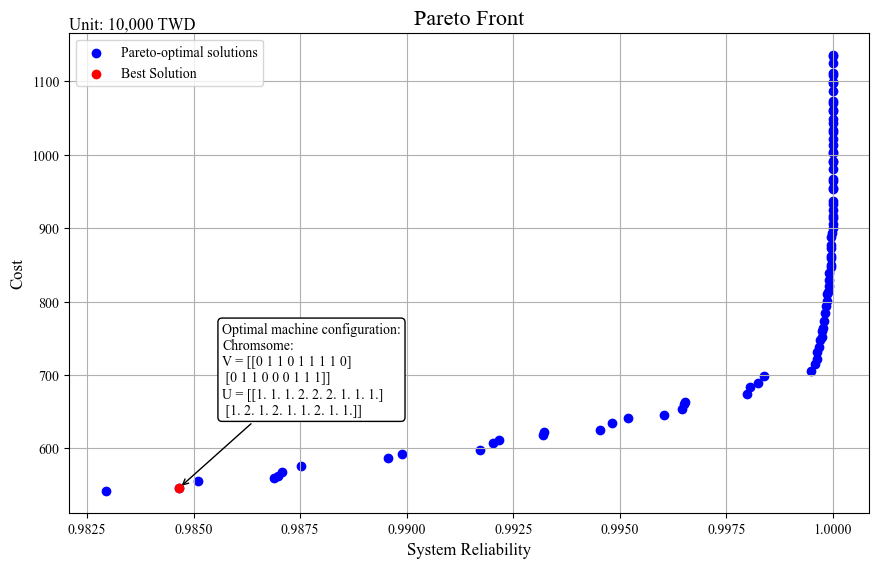

In [59]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

def y_axis_formatter(x, pos):
    return f'{x/10000:.0f}'
    
def x_axis_formatter(x, pos):
    return f'{x:.3f}'

Pareto_Chrom = []
Pareto_Chrom_Num = []
Pareto_Sys = []
Pareto_Cost = []

for i in Combination_F[0]:  
    should_append = True  # 預設要加入

    for chrom, chrom_num in zip(Pareto_Chrom, Pareto_Chrom_Num):
        if np.array_equal(chrom, Combination_Population[i]) and np.array_equal(chrom_num, Combination_Population_Num[i]):
            should_append = False  # 發現完全相同的組合，就不加入
            break  # 提前結束內層迴圈，因為已經確定不需要 append

    if should_append:
        Pareto_Chrom.append(Combination_Population[i])
        Pareto_Chrom_Num.append(Combination_Population_Num[i])
        Pareto_Sys.append(Combination_S[i])
        Pareto_Cost.append(Combination_C[i])

# Plot the Pareto front
plt.figure(figsize=(10, 6))
plt.scatter(Pareto_Sys, Pareto_Cost, color='b', label='Pareto-optimal solutions')

# Step 1: Decision Matrix
Data_Matrix = np.column_stack((Pareto_Sys, Pareto_Cost))
Weight_Matrix = [0.7, 0.3]
Benefit_attributes = set([0])  # Benefit type (Step 4)
Rows, Cols = Data_Matrix.shape

# Step 2: Normalize
Normalize_Rate = np.zeros(Cols)
Normalize_Matrix = np.zeros((Rows, Cols))
for i in range(Cols):
    for j in range(Rows):
        Normalize_Rate[i] += (Data_Matrix[j][i])**2

for i in range(Cols):
    Normalize_Rate[i] = np.sqrt(Normalize_Rate[i])

for i in range(Cols):
    for j in range(Rows): 
        Normalize_Matrix[j][i] = Data_Matrix[j][i] / Normalize_Rate[i]

# Step 3: Weight
Weighted_Normalize_Matrix = np.zeros((Rows, Cols))
for i in range(Cols):
    for j in range(Rows): 
        Weighted_Normalize_Matrix[j][i] = Normalize_Matrix[j][i] * Weight_Matrix[i]

# Step 4: Positive and Negative Ideal Solutions
a_pos = np.zeros(Cols)
a_neg = np.zeros(Cols)

for i in range(Cols):    
    column = Weighted_Normalize_Matrix[:, i]
    max_val = np.max(column)
    min_val = np.min(column)
    
    if i in Benefit_attributes:
        a_pos[i] = max_val
        a_neg[i] = min_val
    else:
        a_pos[i] = min_val
        a_neg[i] = max_val

# Step 5: Distances
s_pos = np.zeros(Rows)
s_neg = np.zeros(Rows)

for j in range(Rows):
    for i in range(Cols):
        s_pos[j] += (Weighted_Normalize_Matrix[j][i] - a_pos[i])**2
        s_neg[j] += (Weighted_Normalize_Matrix[j][i] - a_neg[i])**2

s_pos = np.sqrt(s_pos)
s_neg = np.sqrt(s_neg)

# Step 6: Ideal Solution
S = np.zeros(Rows)
for j in range(Rows):
    S[j] = s_neg[j] / (s_pos[j] + s_neg[j])

# Step 7: Ranking
Sorted_indices = np.argsort(S)[::-1]

# Get the best solution index (first one after sorting)
best_index = Sorted_indices[0]
best_chrom = Pareto_Chrom[best_index]
best_chrom_num = Pareto_Chrom_Num[best_index]

# Print the best solution details
print(f"Best Chromosome_Index: {best_index}")
print(f"Best Chromosome_: {best_chrom}")
print(f"Best Chromosome_Num: {best_chrom_num}")
print(f"System reliability: {Pareto_Sys[best_index]}")
print(f"Cost: {Pareto_Cost[best_index]}")

# Highlight the best solution on the Pareto plot
plt.scatter(Pareto_Sys[best_index], Pareto_Cost[best_index], color='r', label='Best Solution', zorder=5)

# Add annotation for the best solution
best_text = f'Optimal machine configuration:\nChromsome:\nV = {best_chrom}\nU = {best_chrom_num}'
plt.annotate(best_text,
             xy=(Pareto_Sys[best_index], Pareto_Cost[best_index]), 
             xytext=(Pareto_Sys[best_index]+ 0.001,Pareto_Cost[best_index] + 1000000),  
             fontsize=10, fontname='Times New Roman',
             bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white"),
             arrowprops=dict(arrowstyle="->", color='black'))

# Set title and labels
plt.title('Pareto Front', fontsize=16, fontname='Times New Roman')
plt.xlabel('System Reliability', fontsize=12, fontname='Times New Roman')
plt.ylabel('Cost', fontsize=12, fontname='Times New Roman')
plt.text(plt.gca().get_xlim()[0], plt.gca().get_ylim()[1], 'Unit: 10,000 TWD', fontsize=12, fontname='Times New Roman', verticalalignment='bottom')

plt.gca().yaxis.set_major_formatter(FuncFormatter(y_axis_formatter))


# 設定 x/y 軸數值的字型
for label in plt.gca().get_xticklabels():
    label.set_fontname('Times New Roman')

for label in plt.gca().get_yticklabels():
    label.set_fontname('Times New Roman')

# Add grid, legend, and adjust margins
plt.grid(True)
plt.legend(prop={'family': 'Times New Roman'})

# Set the margins/borders (edges of the plot)
plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)

plt.savefig('pareto_front_optimal.png', bbox_inches='tight')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

def y_axis_formatter(x, pos):
    return f'{x/10000:.0f}'
    
def x_axis_formatter(x, pos):
    return f'{x:.3f}'

Pareto_Chrom = []
Pareto_Chrom_Num = []
Pareto_Sys = []
Pareto_Cost = []

for i in Combination_F[0]:  
    should_append = True  # 預設要加入

    for chrom, chrom_num in zip(Pareto_Chrom, Pareto_Chrom_Num):
        if np.array_equal(chrom, Combination_Population[i]) and np.array_equal(chrom_num, Combination_Population_Num[i]):
            should_append = False  # 發現完全相同的組合，就不加入
            break  # 提前結束內層迴圈，因為已經確定不需要 append

    if should_append:
        Pareto_Chrom.append(Combination_Population[i])
        Pareto_Chrom_Num.append(Combination_Population_Num[i])
        Pareto_Sys.append(Combination_S[i])
        Pareto_Cost.append(Combination_C[i])

# Plot the Pareto front
plt.figure(figsize=(10, 6))
plt.scatter(Pareto_Sys, Pareto_Cost, color='b', label='Pareto-optimal solutions')

# Step 1: Decision Matrix
Data_Matrix = np.column_stack((Pareto_Sys, Pareto_Cost))
Weight_Matrix = [0.7, 0.3]
Benefit_attributes = set([0])  # Benefit type (Step 4)
Rows, Cols = Data_Matrix.shape

# Step 2: Normalize
Normalize_Rate = np.zeros(Cols)
Normalize_Matrix = np.zeros((Rows, Cols))
for i in range(Cols):
    for j in range(Rows):
        Normalize_Rate[i] += (Data_Matrix[j][i])**2

for i in range(Cols):
    Normalize_Rate[i] = np.sqrt(Normalize_Rate[i])

for i in range(Cols):
    for j in range(Rows): 
        Normalize_Matrix[j][i] = Data_Matrix[j][i] / Normalize_Rate[i]

# Step 3: Weight
Weighted_Normalize_Matrix = np.zeros((Rows, Cols))
for i in range(Cols):
    for j in range(Rows): 
        Weighted_Normalize_Matrix[j][i] = Normalize_Matrix[j][i] * Weight_Matrix[i]

# Step 4: Positive and Negative Ideal Solutions
a_pos = np.zeros(Cols)
a_neg = np.zeros(Cols)

for i in range(Cols):    
    column = Weighted_Normalize_Matrix[:, i]
    max_val = np.max(column)
    min_val = np.min(column)
    
    if i in Benefit_attributes:
        a_pos[i] = max_val
        a_neg[i] = min_val
    else:
        a_pos[i] = min_val
        a_neg[i] = max_val
# Step 5: Distances
s_pos = np.zeros(Rows)
s_neg = np.zeros(Rows)

for j in range(Rows):
    for i in range(Cols):
        s_pos[j] += (Weighted_Normalize_Matrix[j][i] - a_pos[i])**2
        s_neg[j] += (Weighted_Normalize_Matrix[j][i] - a_neg[i])**2

s_pos = np.sqrt(s_pos)
s_neg = np.sqrt(s_neg)

# Step 6: Ideal Solution
S = np.zeros(Rows)
for j in range(Rows):
    S[j] = s_neg[j] / (s_pos[j] + s_neg[j])
# Step 7: Ranking
Sorted_indices = np.argsort(S)[::-1]

# Get the best solution index (first one after sorting)
best_index = Sorted_indices[0]
best_chrom = Pareto_Chrom[best_index]
best_chrom_num = Pareto_Chrom_Num[best_index]

# Print the best solution details
print(f"Best Chromosome_Index: {best_index}")
print(f"Best Chromosome_: {best_chrom}")
print(f"Best Chromosome_Num: {best_chrom_num}")
print(f"System reliability: {Pareto_Sys[best_index]}")
print(f"Cost: {Pareto_Cost[best_index]}")

# Highlight the best solution on the Pareto plot
plt.scatter(Pareto_Sys[best_index], Pareto_Cost[best_index], color='r', label='Best Solution', zorder=5)

# Add annotation for the best solution
best_text = f'Optimal machine configuration:\nChromsome:\nV = {best_chrom}\nU = {best_chrom_num}'
plt.annotate(best_text,
             xy=(Pareto_Sys[best_index], Pareto_Cost[best_index]), 
             xytext=(Pareto_Sys[best_index] + 0.02, Pareto_Cost[best_index] + 20000),  
             fontsize=10, fontname='Times New Roman',
             bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white"),
             arrowprops=dict(arrowstyle="->", color='black'))

# Set title and labels
plt.title('Pareto Front', fontsize=16, fontname='Times New Roman')
plt.xlabel('System Reliability', fontsize=12, fontname='Times New Roman')
plt.ylabel('Cost', fontsize=12, fontname='Times New Roman')
plt.text(plt.gca().get_xlim()[0], plt.gca().get_ylim()[1], 'Unit: 10,000 TWD', fontsize=12, fontname='Times New Roman', verticalalignment='bottom')

plt.gca().yaxis.set_major_formatter(FuncFormatter(y_axis_formatter))


# 設定 x/y 軸數值的字型
for label in plt.gca().get_xticklabels():
    label.set_fontname('Times New Roman')

for label in plt.gca().get_yticklabels():
    label.set_fontname('Times New Roman')

# Add grid, legend, and adjust margins
plt.grid(True)
plt.legend(prop={'family': 'Times New Roman'})

# Set the margins/borders (edges of the plot)
plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)

#plt.savefig('pareto_front_compare.png', bbox_inches='tight')
plt.show()